# MSBD 566 — Model Optimization
## Hands-On Practice Notebook

Everything from class, rebuilt with your own hands: cross-validation variants, the nested-CV bug, bias-variance, learning curves, grid vs. random search, successive halving, and automated model selection. Same dataset we've used all semester.

No instructor walking you through this one, so read the markdown before each section, run the code, and actually look at the numbers before moving on.

| Step | What you'll do |
|---|---|
| 0 | Load the data, build the same 8-feature dataset from class |
| 1 | Compare KFold, StratifiedKFold, StratifiedGroupKFold |
| 2 | Check whether k=3, 5, or 10 actually matters on our data |
| 3 | Reproduce the discussion-board bug, and the honest fix |
| 4 | Diagnose underfitting vs. overfitting with real numbers |
| 5 | Build a real learning curve |
| 6 | Grid search vs. random search, head to head |
| 7 | Successive halving |
| 8 | Automated model selection across algorithms |
| 9 | Challenge questions — **no AI** |


---
## Step 0 — Setup


In [1]:
import os
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"
if not os.path.exists("diabetic_data.csv"):
    urllib.request.urlretrieve(DATA_URL, "diabetes_data.zip")
    with zipfile.ZipFile("diabetes_data.zip") as z:
        z.extractall(".")

data = pd.read_csv("diabetic_data.csv")
data = data.replace('?', np.nan)
data = data[~data['discharge_disposition_id'].isin([11, 13, 14, 19, 20, 21])]
data = data[data['gender'] != 'Unknown/Invalid']
data['readmit_30'] = (data['readmitted'] == '<30').astype(int)

age_order = ['[0-10)','[10-20)','[20-30)','[30-40)','[40-50)','[50-60)','[60-70)','[70-80)','[80-90)','[90-100)']
age_map = {b: i for i, b in enumerate(age_order)}
data['age_ord'] = data['age'].map(age_map)

FEATURES = ['age_ord', 'time_in_hospital', 'num_lab_procedures', 'num_medications',
            'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
TARGET = 'readmit_30'

sub = data[FEATURES + [TARGET, 'patient_nbr']].dropna()
X = sub[FEATURES]
y = sub[TARGET]
groups = sub['patient_nbr']

print(X.shape, y.mean())

(99340, 8) 0.1138916851218039


---
## Step 1 — KFold vs. StratifiedKFold vs. StratifiedGroupKFold

Plain KFold can let the class balance wobble fold to fold, purely by chance. StratifiedKFold locks that down. But StratifiedKFold alone doesn't know about repeat patients. StratifiedGroupKFold does both at once.


In [2]:
from sklearn.model_selection import KFold, StratifiedKFold, StratifiedGroupKFold

def fold_rates(splitter, use_groups=False):
    rates = []
    if use_groups:
        for tr, te in splitter.split(X, y, groups=groups):
            rates.append(y.iloc[te].mean())
    else:
        for tr, te in splitter.split(X, y):
            rates.append(y.iloc[te].mean())
    return rates

kf_rates = fold_rates(KFold(n_splits=5, shuffle=True, random_state=42))
skf_rates = fold_rates(StratifiedKFold(n_splits=5, shuffle=True, random_state=42))
sgkf_rates = fold_rates(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42), use_groups=True)

for name, rates in [("KFold", kf_rates), ("StratifiedKFold", skf_rates), ("StratifiedGroupKFold", sgkf_rates)]:
    print(f"{name:22s} range={max(rates)-min(rates):.4f}  rates={[round(r,4) for r in rates]}")

overlap = False
for tr, te in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(X, y, groups=groups):
    if set(groups.iloc[tr]) & set(groups.iloc[te]):
        overlap = True
print("Patient overlap with StratifiedGroupKFold:", overlap)

KFold                  range=0.0032  rates=[np.float64(0.1126), np.float64(0.1122), np.float64(0.1139), np.float64(0.1155), np.float64(0.1153)]
StratifiedKFold        range=0.0001  rates=[np.float64(0.1139), np.float64(0.1139), np.float64(0.1139), np.float64(0.1139), np.float64(0.1139)]
StratifiedGroupKFold   range=0.0001  rates=[np.float64(0.1139), np.float64(0.1139), np.float64(0.1139), np.float64(0.1139), np.float64(0.1139)]
Patient overlap with StratifiedGroupKFold: False


---
## Step 2 — Does k Actually Matter Here?

The textbook argument: small k means more bias, large k means more expensive and more correlated fits. Check it on our own data.


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score

model = LogisticRegression(max_iter=1000)
for k in [3, 5, 10]:
    scores = cross_val_score(model, X, y, groups=groups, cv=GroupKFold(n_splits=k), scoring='roc_auc')
    print(f"k={k:2d}  mean={scores.mean():.4f}  std={scores.std():.4f}")

k= 3  mean=0.6341  std=0.0014
k= 5  mean=0.6342  std=0.0064
k=10  mean=0.6342  std=0.0110


Compare the `mean` and `std` across the three values of k. At this sample size, do you see the textbook's bias-variance argument playing out, or something closer to "it barely matters"? Keep this result in mind for Challenge Question 1.


---
## Step 3 — The Discussion Board Bug, Reproduced

`GridSearchCV.best_score_` answers a subtly different question than "how will this model do on new patients." Fit it both the naive way and the honest, nested way, and compare.


In [4]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score

param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100]}

naive_search = GridSearchCV(LogisticRegression(max_iter=1000), param_grid,
                             cv=GroupKFold(n_splits=5), scoring='roc_auc')
naive_search.fit(X, y, groups=groups)
print("Naive best_score_:", round(naive_search.best_score_, 4), "  best C:", naive_search.best_params_['C'])

Naive best_score_: 0.6342   best C: 1


In [5]:
outer = GroupKFold(n_splits=5)
nested_scores = []
chosen_Cs = []

for train_idx, test_idx in outer.split(X, y, groups=groups):
    X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
    y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]
    groups_tr = groups.iloc[train_idx]

    inner = GridSearchCV(LogisticRegression(max_iter=1000), param_grid,
                          cv=GroupKFold(n_splits=4), scoring='roc_auc')
    inner.fit(X_tr, y_tr, groups=groups_tr)
    chosen_Cs.append(inner.best_params_['C'])

    probs = inner.predict_proba(X_te)[:, 1]
    nested_scores.append(roc_auc_score(y_te, probs))

nested_scores = np.array(nested_scores)
print("Nested mean:", round(nested_scores.mean(), 4), "  std:", round(nested_scores.std(), 4))
print("C chosen per fold:", chosen_Cs)
print("Optimism gap:", round(naive_search.best_score_ - nested_scores.mean(), 4))

Nested mean: 0.6341   std: 0.0064
C chosen per fold: [10, 100, 1, 10, 0.01]
Optimism gap: 0.0


---
## Step 4 — Underfitting vs. Overfitting

Vary a decision tree's `max_depth` and watch training and cross-validated error diverge.


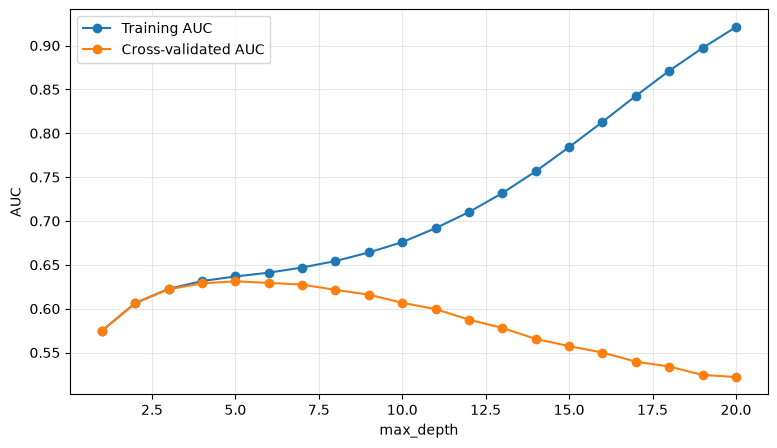

In [6]:
from sklearn.tree import DecisionTreeClassifier

depths = range(1, 21)
train_aucs, cv_aucs = [], []

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    tr_scores, te_scores = [], []
    for train_idx, test_idx in GroupKFold(n_splits=5).split(X, y, groups=groups):
        tree.fit(X.iloc[train_idx], y.iloc[train_idx])
        tr_scores.append(roc_auc_score(y.iloc[train_idx], tree.predict_proba(X.iloc[train_idx])[:, 1]))
        te_scores.append(roc_auc_score(y.iloc[test_idx], tree.predict_proba(X.iloc[test_idx])[:, 1]))
    train_aucs.append(np.mean(tr_scores))
    cv_aucs.append(np.mean(te_scores))

plt.figure(figsize=(9, 5))
plt.plot(depths, train_aucs, label='Training AUC', marker='o')
plt.plot(depths, cv_aucs, label='Cross-validated AUC', marker='o')
plt.xlabel('max_depth')
plt.ylabel('AUC')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Find the depth where the gap between the two lines starts widening. That's the point where the tree starts overfitting — everything past it is memorization, not learning.


---
## Step 5 — A Real Learning Curve

Would more patients actually help, or has this model already plateaued?


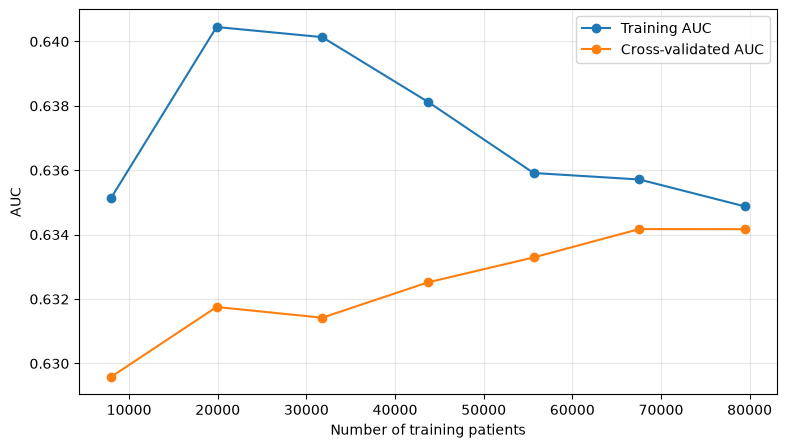

In [7]:
from sklearn.model_selection import learning_curve

sizes, train_scores, test_scores = learning_curve(
    LogisticRegression(max_iter=1000), X, y, groups=groups,
    cv=GroupKFold(n_splits=5), train_sizes=[0.1, 0.25, 0.4, 0.55, 0.7, 0.85, 1.0],
    scoring='roc_auc', n_jobs=-1
)

plt.figure(figsize=(9, 5))
plt.plot(sizes, train_scores.mean(axis=1), label='Training AUC', marker='o')
plt.plot(sizes, test_scores.mean(axis=1), label='Cross-validated AUC', marker='o')
plt.xlabel('Number of training patients')
plt.ylabel('AUC')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

---
## Step 6 — Grid Search vs. Random Search

Same budget, same data, two strategies.


In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

X_small = X.sample(n=20000, random_state=42)
y_small = y.loc[X_small.index]
groups_small = groups.loc[X_small.index]
cv3 = GroupKFold(n_splits=3)

grid_params = {'n_estimators': [50, 100, 150, 200], 'max_depth': [3, 6, 9, 12]}
grid = GridSearchCV(RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1),
                     grid_params, cv=cv3, scoring='roc_auc')
grid.fit(X_small, y_small, groups=groups_small)

rand_params = {'n_estimators': randint(50, 210), 'max_depth': randint(3, 13)}
rand = RandomizedSearchCV(RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1),
                           rand_params, n_iter=16, cv=cv3, scoring='roc_auc', random_state=42)
rand.fit(X_small, y_small, groups=groups_small)

print("Grid best:  ", grid.best_params_, round(grid.best_score_, 4))
print("Random best:", rand.best_params_, round(rand.best_score_, 4))

Grid best:   {'max_depth': 6, 'n_estimators': 200} 0.6372
Random best: {'max_depth': 5, 'n_estimators': 157} 0.6375


Look at `max_depth` in each result. Did random search land on a value the grid's fixed steps couldn't have reached?


---
## Step 7 — Successive Halving

Same search space as Step 6, but candidates that look bad early get dropped before they waste a full training run.


In [9]:
import time
import warnings
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingRandomSearchCV

t0 = time.time()
with warnings.catch_warnings():
    warnings.filterwarnings('ignore')
    halving = HalvingRandomSearchCV(RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1),
                                     rand_params, cv=cv3, scoring='roc_auc', random_state=42,
                                     factor=2, min_resources=3000)
    halving.fit(X_small, y_small, groups=groups_small)
halving_time = time.time() - t0

print("Halving best:", halving.best_params_, round(halving.best_score_, 4))
print("Time:", round(halving_time, 1), "seconds")
print("n_resources_ per round:", halving.n_resources_)
print("n_candidates_ per round:", halving.n_candidates_)

Halving best: {'max_depth': 6, 'n_estimators': 153} 0.6388
Time: 17.4 seconds
n_resources_ per round: [3000, 6000, 12000]
n_candidates_ per round: [6, 3, 2]


---
## Step 8 — Automated Model Selection

Nested CV, run once per algorithm, so the comparison is fair.


In [10]:
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X)
X_scaled = pd.DataFrame(scaler.transform(X), columns=FEATURES, index=X.index)

candidates = {
    'Logistic Regression': (LogisticRegression(max_iter=1000), X),
    'Decision Tree': (DecisionTreeClassifier(max_depth=5, random_state=42), X),
    'Random Forest': (RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1), X),
}

results = {}
for name, (est, feats) in candidates.items():
    scores = cross_val_score(est, feats, y, groups=groups, cv=GroupKFold(n_splits=5), scoring='roc_auc')
    results[name] = (scores.mean(), scores.std())

for name, (mean, std) in sorted(results.items(), key=lambda kv: -kv[1][0]):
    print(f"{name:22s} {mean:.4f} +/- {std:.4f}")

Random Forest          0.6376 +/- 0.0068
Logistic Regression    0.6342 +/- 0.0064
Decision Tree          0.6312 +/- 0.0057


---
## 🏆 Challenge Questions

> ⚠️ **No AI for these.** Work through them yourself first.

**C1.** In Step 2, did the choice of k change the mean AUC by more than the std you saw at any single k? What does that tell you about whether the differences between k=3, 5, and 10 are meaningful here, or just noise?

**C2.** In Step 3, was the optimism gap bigger or smaller than the class example computed in lecture? Try shrinking `param_grid` to just `[0.01, 1, 100]` — does the gap change? Why might a smaller grid change how much room there is for optimism bias?

**C3.** In Step 4, find the exact `max_depth` where cross-validated AUC peaks, then declines. Refit a single tree at that depth and report its test AUC on a held-out GroupShuffleSplit test set.

**C4.** In Step 6, increase `n_iter` for random search to 40 while keeping the grid fixed at 16. Does random search's advantage grow, shrink, or stay about the same?

**C5 (stretch).** Add `SVM (linear)` to the candidates dictionary in Step 8, using `LinearSVC` with `X_scaled` instead of `X`. Note that `LinearSVC` has no `predict_proba`, so you'll need `cross_val_score` with a `make_scorer` around `decision_function`, or switch scoring to `'accuracy'` for this one candidate. Which of the four wins?


In [11]:
# C1
k_summary = []
for k in [3, 5, 10]:
    scores = cross_val_score(LogisticRegression(max_iter=1000), X, y,
                             groups=groups, cv=GroupKFold(n_splits=k), scoring='roc_auc')
    k_summary.append({'k': k, 'mean AUC': scores.mean(), 'std AUC': scores.std()})
k_table = pd.DataFrame(k_summary)
print(k_table.round(4).to_string(index=False))
mean_range = k_table['mean AUC'].max() - k_table['mean AUC'].min()
smallest_std = k_table['std AUC'].min()
print(f"C1: largest change in mean AUC = {mean_range:.4f}; smallest fold std = {smallest_std:.4f}")
if mean_range > smallest_std:
    print('At least one mean difference exceeds the smallest within-k standard deviation, but this by itself does not prove k matters.')
else:
    print('The variation between the k choices is smaller than every within-k standard deviation, suggesting mostly fold-to-fold noise.')

 k  mean AUC  std AUC
 3    0.6341   0.0014
 5    0.6342   0.0064
10    0.6342   0.0110
C1: largest change in mean AUC = 0.0000; smallest fold std = 0.0014
The variation between the k choices is smaller than every within-k standard deviation, suggesting mostly fold-to-fold noise.


In [12]:
# C2
small_grid = {'C': [0.01, 1, 100]}
small_naive = GridSearchCV(LogisticRegression(max_iter=1000), small_grid,
                            cv=GroupKFold(n_splits=5), scoring='roc_auc')
small_naive.fit(X, y, groups=groups)
small_nested_scores = []
for train_idx, test_idx in GroupKFold(n_splits=5).split(X, y, groups=groups):
    inner = GridSearchCV(LogisticRegression(max_iter=1000), small_grid,
                         cv=GroupKFold(n_splits=4), scoring='roc_auc')
    inner.fit(X.iloc[train_idx], y.iloc[train_idx], groups=groups.iloc[train_idx])
    p = inner.predict_proba(X.iloc[test_idx])[:, 1]
    small_nested_scores.append(roc_auc_score(y.iloc[test_idx], p))
small_gap = small_naive.best_score_ - np.mean(small_nested_scores)
original_gap = naive_search.best_score_ - nested_scores.mean()
print(f'C2: Original grid optimism gap: {original_gap:.4f}')
print(f'C2: Reduced grid optimism gap:  {small_gap:.4f}')

C2: Original grid optimism gap: 0.0000
C2: Reduced grid optimism gap:  0.0000


A smaller grid gives the search fewer chances to select a configuration that looks unusually good due to fold-level noise

In [13]:
# C3
from sklearn.model_selection import GroupShuffleSplit
best_depth_idx = int(np.argmax(cv_aucs))
best_depth = list(depths)[best_depth_idx]
print(f'C3: Peak cross-validated AUC={cv_aucs[best_depth_idx]:.4f} at max_depth={best_depth}')
if best_depth_idx < len(cv_aucs)-1:
    print(f'AUC at next depth ({list(depths)[best_depth_idx+1]}) = {cv_aucs[best_depth_idx+1]:.4f}')
else:
    print('Peak occurs at the maximum evaluated depth, so a decline after the peak is not established.')
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(X, y, groups=groups))
peak_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42).fit(X.iloc[tr], y.iloc[tr])
peak_test_auc = roc_auc_score(y.iloc[te], peak_tree.predict_proba(X.iloc[te])[:, 1])
print(f'Group-held-out test AUC at max_depth={best_depth}: {peak_test_auc:.4f}')

C3: Peak cross-validated AUC=0.6312 at max_depth=5
AUC at next depth (6) = 0.6294
Group-held-out test AUC at max_depth=5: 0.6365


In [14]:
# C4
rand_40 = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1),
    rand_params, n_iter=40, cv=cv3, scoring='roc_auc', random_state=42
)
rand_40.fit(X_small, y_small, groups=groups_small)
old_advantage = rand.best_score_ - grid.best_score_
new_advantage = rand_40.best_score_ - grid.best_score_
print(f'C4: Grid (16): {grid.best_score_:.4f} | Random (16): {rand.best_score_:.4f} | Random (40): {rand_40.best_score_:.4f}')
print('Best random (40) parameters:', rand_40.best_params_)
print(f'Advantage over grid: before={old_advantage:+.4f}; after={new_advantage:+.4f}')
if new_advantage > old_advantage:
    print('Random search advantage grew with the additional configurations.')
elif new_advantage < old_advantage:
    print('Random search advantage shrank (this can happen with CV variability).')
else:
    print('Random search advantage stayed the same.')

C4: Grid (16): 0.6372 | Random (16): 0.6375 | Random (40): 0.6378
Best random (40) parameters: {'max_depth': 4, 'n_estimators': 183}
Advantage over grid: before=+0.0004; after=+0.0007
Random search advantage grew with the additional configurations.


In [15]:
# C5 (stretch)
candidates_c5 = dict(candidates)
candidates_c5['SVM (linear)'] = (LinearSVC(max_iter=5000, random_state=42), X_scaled)
results_c5 = {}
for name, (est, feats) in candidates_c5.items():
    # roc_auc works with SVM's decision_function; predict_proba is unnecessary
    scores = cross_val_score(est, feats, y, groups=groups,
                             cv=GroupKFold(n_splits=5), scoring='roc_auc')
    results_c5[name] = (scores.mean(), scores.std())
for name, (mean, std) in sorted(results_c5.items(), key=lambda kv: -kv[1][0]):
    print(f'{name:22s} {mean:.4f} +/- {std:.4f}')
winner = max(results_c5, key=lambda name: results_c5[name][0])
print(f'C5: Best mean group CV AUC: {winner} ({results_c5[winner][0]:.4f})')

Random Forest          0.6376 +/- 0.0068
SVM (linear)           0.6368 +/- 0.0057
Logistic Regression    0.6342 +/- 0.0064
Decision Tree          0.6312 +/- 0.0057
C5: Best mean group CV AUC: Random Forest (0.6376)
